# AlexNet CNN encoder — trained from scratch on the augmented dataset

Trains an **AlexNet** encoder (`src/models/encoders/alexnet.py`) from random weights for
200-class bird classification on CUB-200-2011, using the **originals + Task 1.1 augmented copies**
from `src/data` (`data.use_offline_augmented=true`).

All logic lives in `src/` (same data split, normalisation, training loop, evaluation and Grad-CAM as the
from-scratch ResNet); this notebook only configures and runs it. Settings are in `configs/cls_alexnet.yaml`.

**Architecture** (input 224×224):

| layer | output | notes |
|---|---|---|
| conv1 11×11/4, 96 | 55×55 | `c1` |
| maxpool 3/2 → conv2 5×5, 256 | 27×27 | `c2` |
| maxpool 3/2 → conv3 3×3, 384 | 13×13 | `c3` |
| conv4 3×3, 384 | 13×13 | `c4` |
| conv5 3×3, 256 | 13×13 | `c5`, Grad-CAM layer |
| maxpool 3/2 → FC6 4096 → FC7 4096 (dropout 0.5) | 4096 | encoder output (`pooled`) |
| FC8 200 | 200 | classifier head |

BatchNorm replaces the original Local Response Normalisation so the network trains well from scratch.

**Where to run.** A GPU is strongly recommended (~1–2 min/epoch on a T4 vs ~11 min on CPU).

**Secrets.** `GITHUB_TOKEN` is only needed while the repo is private and `WANDB_API_KEY` is optional (without it,
tracking is disabled). They are never stored in the repository: `.env` is git-ignored, so each environment gets them
from its own place, as described below.

- **VS Code with a Colab kernel**: the notebook runs on the Colab server, which cannot see your local files. Connect
  to a T4 GPU, then in the Explorer right-click `.env` → *Upload to Colab*, and run the notebook. New Colab servers
  start empty, so upload it again after getting a new one. The notebook clones the `AlexNet` branch, so the branch
  must be pushed to GitHub. Results are written to `/content/outputs` and zipped into
  `/content/alexnet_results.zip` at the end; `.env` is not included. Download them before removing the server.
- **Google Colab in the browser** (T4): *Runtime → Change runtime type → T4 GPU*. Add the Colab secrets
  `GITHUB_TOKEN` and `WANDB_API_KEY`, or the notebook asks for them in a hidden input box. Results are also copied to
  Google Drive (`MyDrive/alexnet_outputs`) when Drive can be mounted.
- **Kaggle**: enable *GPU* and *Internet*, add the secrets `GITHUB_TOKEN` (and `WANDB_API_KEY`), then *Save & Run All*.
  Do not put a `.env` in `/kaggle/working`: that folder is saved as the notebook output.
- **Locally on your own GPU**: run it from the `notebooks/` folder with a CUDA build of PyTorch. Secrets are read
  from the `.env` file in the repo root.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

ON_KAGGLE = os.path.exists("/kaggle/working")
try:
    import google.colab  # noqa: F401
    ON_COLAB = True
except ImportError:
    ON_COLAB = False


def load_env():
    # Load KEY=value lines from a .env kept outside git; values already in the environment win.
    # Looks next to the notebook / repo root, then in the Colab server's /content (VS Code: right-click
    # .env > Upload to Colab), then in Google Drive if it is already mounted
    folders = (Path.cwd(), Path.cwd().parent, Path("/content"), Path("/content/drive/MyDrive"))
    env_file = next((f / ".env" for f in folders if (f / ".env").exists()), None)
    if env_file is None:
        print("No .env file found" + (" (VS Code: right-click .env > Upload to Colab, then rerun)" if ON_COLAB else ""))
        return
    print("Secrets loaded from", env_file)
    for line in env_file.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            key, value = line.split("=", 1)
            os.environ.setdefault(key.strip(), value.strip().strip("'\""))


def get_secret(name):
    # Read a secret from the .env file, then Kaggle / Colab; None when it is not set
    if name in os.environ:
        return os.environ[name]
    try:
        if ON_KAGGLE:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret(name)
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None


def ask_secret(name, purpose):
    # Colab only, when there is no .env or Colab secret: the typed value is hidden and never saved
    if not ON_COLAB:
        return None
    from getpass import getpass
    print(f"Waiting for {name} in the input box (top of the window in VS Code)")
    return getpass(f"{name} ({purpose}, leave blank to skip): ").strip() or None


load_env()
WANDB_API_KEY = get_secret("WANDB_API_KEY") or ask_secret("WANDB_API_KEY", "experiment tracking")
if WANDB_API_KEY:
    os.environ["WANDB_API_KEY"] = WANDB_API_KEY
else:
    print("No WANDB_API_KEY secret: tracking disabled")

if ON_KAGGLE or ON_COLAB:
    # A token is only needed while the repo is private
    GITHUB_TOKEN = get_secret("GITHUB_TOKEN") or ask_secret("GITHUB_TOKEN", "only while the repo is private")
    credentials = f"{GITHUB_TOKEN}@" if GITHUB_TOKEN else ""

    REPO = "omarsaher/image-classfication-and-caption"
    BRANCH = "AlexNet"
    WORKDIR = "/tmp/repo" if ON_KAGGLE else "/content/repo"                          # code + data
    OUTPUTS = "/kaggle/working/outputs" if ON_KAGGLE else "/content/outputs"         # results

    # Clone the repo; the token is removed from the remote URL right after
    if not os.path.exists(WORKDIR):
        result = subprocess.run(
            ["git", "clone", "--depth", "1", "-b", BRANCH,
             f"https://{credentials}github.com/{REPO}.git", WORKDIR],
            capture_output=True, text=True, env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
        )
        print("clone exit code:", result.returncode)
        stderr = result.stderr.replace(GITHUB_TOKEN, "***") if GITHUB_TOKEN else result.stderr
        print(stderr[-2000:])
        if result.returncode != 0:
            raise RuntimeError(f"Could not clone branch '{BRANCH}' of {REPO}. Check that the branch is pushed "
                               "and, while the repo is private, that GITHUB_TOKEN can access it.")
        subprocess.run(["git", "-C", WORKDIR, "remote", "set-url", "origin",
                        f"https://github.com/{REPO}.git"], check=True)
    os.environ.pop("GITHUB_TOKEN", None)         # training does not need it
    os.makedirs(OUTPUTS, exist_ok=True)
    if not os.path.exists(f"{WORKDIR}/outputs"):
        os.symlink(OUTPUTS, f"{WORKDIR}/outputs")
    os.chdir(WORKDIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)               # all project paths are relative to the repo root

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import torch

print("repo root:", Path.cwd())
print("torch", torch.__version__, "| device:",
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

No .env file found (VS Code: right-click .env > Upload to Colab, then rerun)
clone exit code: 0
 (7415/16118)
Updating files:  47% (7576/16118)
Updating files:  48% (7737/16118)
Updating files:  49% (7898/16118)
Updating files:  50% (8059/16118)
Updating files:  51% (8221/16118)
Updating files:  52% (8382/16118)
Updating files:  53% (8543/16118)
Updating files:  54% (8704/16118)
Updating files:  55% (8865/16118)
Updating files:  56% (9027/16118)
Updating files:  57% (9188/16118)
Updating files:  58% (9349/16118)
Updating files:  59% (9510/16118)
Updating files:  60% (9671/16118)
Updating files:  61% (9832/16118)
Updating files:  62% (9994/16118)
Updating files:  63% (10155/16118)
Updating files:  64% (10316/16118)
Updating files:  65% (10477/16118)
Updating files:  66% (10638/16118)
Updating files:  67% (10800/16118)
Updating files:  68% (10961/16118)
Updating files:  69% (11122/16118)
Updating files:  70% (11283/16118)
Updating files:  70% (11299/16118)
Updating files:  71% (11444/161

## 1. Configuration

`QUICK_CHECK = True` runs 1 epoch on a few batches to check that everything works before the full run.
Tracking uses Weights & Biases when a `WANDB_API_KEY` is available, otherwise only local files are written.

In [2]:
from src.utils.config import load_config

QUICK_CHECK = False

# Continue an interrupted run: path to its last.pt or best.pt (a history.json next to it restores the curves).
# On Kaggle, a checkpoint in an attached dataset is found automatically
RESUME_FROM = None
if RESUME_FROM is None and ON_KAGGLE and not QUICK_CHECK:
    found = sorted(Path("/kaggle/input").rglob("*.pt"), key=lambda p: p.name != "last.pt")
    RESUME_FROM = str(found[0]) if found else None

overrides = [
    "data.use_offline_augmented=true",       # train on originals + augmented copies
]
if not torch.cuda.is_available():
    overrides += ["data.num_workers=0"]      # avoids worker start-up cost / Windows issues on CPU
elif ON_COLAB:
    overrides += [f"data.num_workers={os.cpu_count()}"]   # Colab has only 2 CPU cores
if not os.environ.get("WANDB_API_KEY"):
    overrides += ["tracking.backend=none"]
if RESUME_FROM:
    overrides += [f"train.resume_from={RESUME_FROM}"]
if QUICK_CHECK:
    overrides += ["experiment.name=alexnet_smoke", "train.epochs=1", "train.warmup_epochs=0",
                  "train.max_batches=3", "data.batch_size=16"]

cfg = load_config("configs/cls_alexnet.yaml", overrides)
RUN_DIR = Path(cfg["experiment"]["output_dir"]) / cfg["experiment"]["name"]
print("run:", cfg["experiment"]["name"], "->", RUN_DIR)
print("resume from:", RESUME_FROM)
print("model:", cfg["model"])
print("train:", cfg["train"])

run: alexnet_augmented -> outputs/classification/alexnet_augmented
resume from: None
model: {'name': 'alexnet', 'num_classes': 200, 'width_mult': 1.0, 'fc_dim': 4096, 'fc_dropout': 0.5, 'batch_norm': True, 'dropout': 0.0}
train: {'epochs': 80, 'lr': 0.0005, 'weight_decay': 0.05, 'warmup_epochs': 5, 'label_smoothing': 0.1, 'early_stopping_patience': 20, 'amp': True, 'save_checkpoint': True, 'max_batches': None, 'resume_from': None}


## 2. Data — originals + augmented copies

200 classes
train images: {'original': 4989, 'augmented': 8407} | total 13396
val images:   {'original': 1000} | total 1000


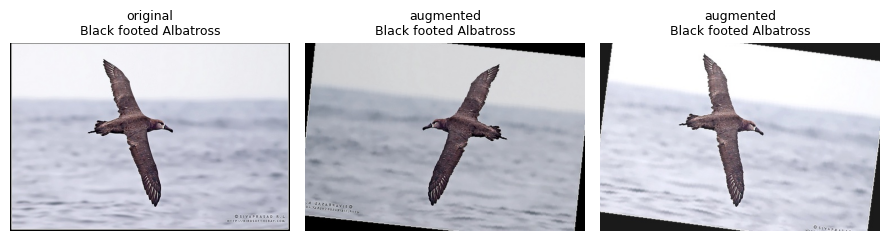

In [3]:
from collections import Counter

import matplotlib.pyplot as plt
from PIL import Image

from src.data.loaders import load_records

train_records, val_records, class_names = load_records(cfg["data"], cfg["experiment"]["seed"])
print(f"{len(class_names)} classes")
print("train images:", dict(Counter(r["image_type"] for r in train_records)), "| total", len(train_records))
print("val images:  ", dict(Counter(r["image_type"] for r in val_records)), "| total", len(val_records))

# One training original next to its augmented copies
by_id = {}
for r in train_records:
    by_id.setdefault(r["original_id"], []).append(r)
group = next(g for g in by_id.values() if len(g) >= 3)
group = sorted(group, key=lambda r: r["image_type"] != "original")[:5]
fig, axes = plt.subplots(1, len(group), figsize=(3 * len(group), 3))
for ax, r in zip(axes, group):
    ax.imshow(Image.open(r["path"]).convert("RGB"))
    ax.set_title(f"{r['image_type']}\n{r['class_name']}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Model

In [4]:
from src.models.registry import build_classifier, count_parameters

model = build_classifier(cfg["model"])
print(model)
print(f"\nparameters: {count_parameters(model):,}")

with torch.no_grad():
    features = model.encoder.forward_features(torch.randn(1, 3, 224, 224))
for name, tensor in features.items():
    print(f"{name:>6}: {tuple(tensor.shape)}")
del model

ImageClassifier(
  (encoder): AlexNet(
    (conv1): Sequential(
      (0): Conv2d(3, 96, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2), bias=False)
      (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (conv2): Sequential(
      (0): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): Sequential(
        (0): Conv2d(96, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (conv3): Sequential(
      (0): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): Sequential(
        (0): Conv2d(256, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(384, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)


## 4. Training

AdamW (no weight decay on biases/BatchNorm), linear warmup + cosine decay, label smoothing, mixed precision on GPU.
The best checkpoint by validation accuracy is saved to `best.pt`; training stops early after
`early_stopping_patience` epochs without improvement.

`last.pt` keeps the full training state after every epoch (about 700 MB) and is removed when training finishes.
If a session is cut off, download `last.pt`, `best.pt` and `history.json` and continue with `RESUME_FROM`.

In [5]:
from src.training.train_classifier import train_classifier

result = train_classifier(cfg)
print(f"best val acc {result.best_val_acc:.4f} at epoch {result.best_epoch} "
      f"({result.epochs_run} epochs, {result.elapsed_sec / 60:.1f} min)")

Run 'alexnet_augmented' on cuda | 59,102,120 parameters | 13396 train / 1000 val images


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: bassil-al-safadi (bassil-al-safadi-ain-shams-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


epoch   1 | train loss 5.330 acc 0.008 | val loss 5.171 acc 0.009


epoch   2 | train loss 5.016 acc 0.024 | val loss 4.989 acc 0.031


epoch   3 | train loss 4.710 acc 0.050 | val loss 4.579 acc 0.056


epoch   4 | train loss 4.467 acc 0.075 | val loss 4.464 acc 0.097


... (74 outputs left out)

epoch  79 | train loss 1.122 acc 0.978 | val loss 3.569 acc 0.331


epoch  80 | train loss 1.120 acc 0.980 | val loss 3.559 acc 0.329


epoch,▁▁▁▂▂▂▃▃▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇███
epoch_time_sec,▇█▆▆▇▃▄▆▃▃▅▅▁▅▄▃▄▆▇▇▂▃▂▄▅▅▅▃▄▆▆▄▃▄▅▃▃▃▃▄
lr,▂▅███████▇▇▇▇▆▆▆▆▅▅▅▅▄▄▄▄▃▃▃▃▂▂▂▂▁▁▁▁▁▁▁
train_acc,▁▁▁▂▂▄▄▆▆▆▇▇▇▇▇▇▇▇▇█████████████████████
train_loss,█▇▇▇▆▅▅▄▄▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_acc,▁▂▃▄▅▆▆▆▆▆▇▇▆▇▇▇▇▇█▇▇███▇█▇█▇███████████
val_loss,█▇▅▅▃▃▂▂▂▂▂▂▂▂▂▂▂▃▂▂▁▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
best_epoch,74
best_val_acc,0.337
checkpoint_path,outputs/classificati...
epoch,80


Best val acc 0.3370 at epoch 74
best val acc 0.3370 at epoch 74 (80 epochs, 48.0 min)


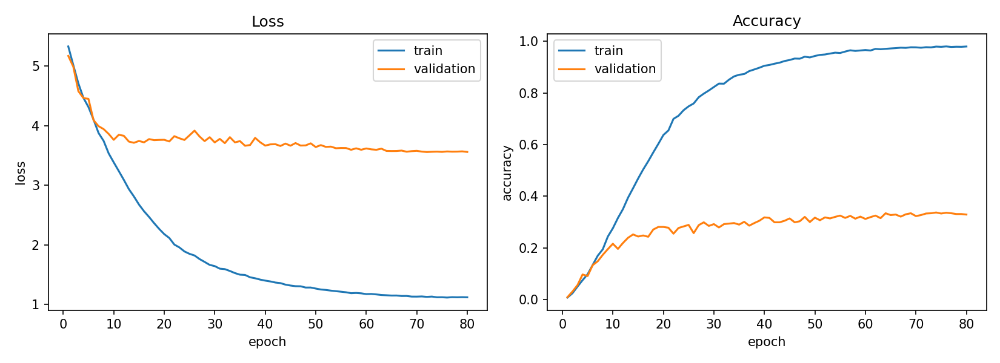

best epoch 74: train acc 0.9793 | val acc 0.3370 | val loss 3.5645


In [6]:
import json

from IPython.display import Image as ShowImage, display

display(ShowImage(filename=str(RUN_DIR / "curves.png")))

with open(RUN_DIR / "history.json", "r", encoding="utf-8") as f:
    history = json.load(f)
best = max(history, key=lambda r: r["val_acc"])
print(f"best epoch {best['epoch']}: train acc {best['train_acc']:.4f} | val acc {best['val_acc']:.4f} "
      f"| val loss {best['val_loss']:.4f}")

## 5. Test-set evaluation (5,794 images)

The CUB test split is downloaded from Hugging Face (`Multimodal-Fatima/CUB_test`) the first time it is used.
With `QUICK_CHECK` the validation split is used instead.

README.md:   0%|          | 0.00/7.15k [00:00<?, ?B/s]

data/test-00000-of-00002-32b23bf2f7b849a(…): reconstructing file:   0%|          |  0.00B /  279MB            

data/test-00000-of-00002-32b23bf2f7b849a(…): downloading bytes:           |  0.00B            

data/test-00001-of-00002-3cd446126954ca1(…): reconstructing file:   0%|          |  0.00B /  286MB            

data/test-00001-of-00002-3cd446126954ca1(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/5794 [00:00<?, ? examples/s]

test_accuracy,0.33069
test_macro_f1,0.3254
test_macro_precision,0.32927
test_macro_recall,0.3342


{
 "accuracy": 0.330686917500863,
 "macro_precision": 0.3292732563030503,
 "macro_recall": 0.3342019267793354,
 "macro_f1": 0.3253972842302613
}
Saved evaluation to outputs/classification/alexnet_augmented/eval_test


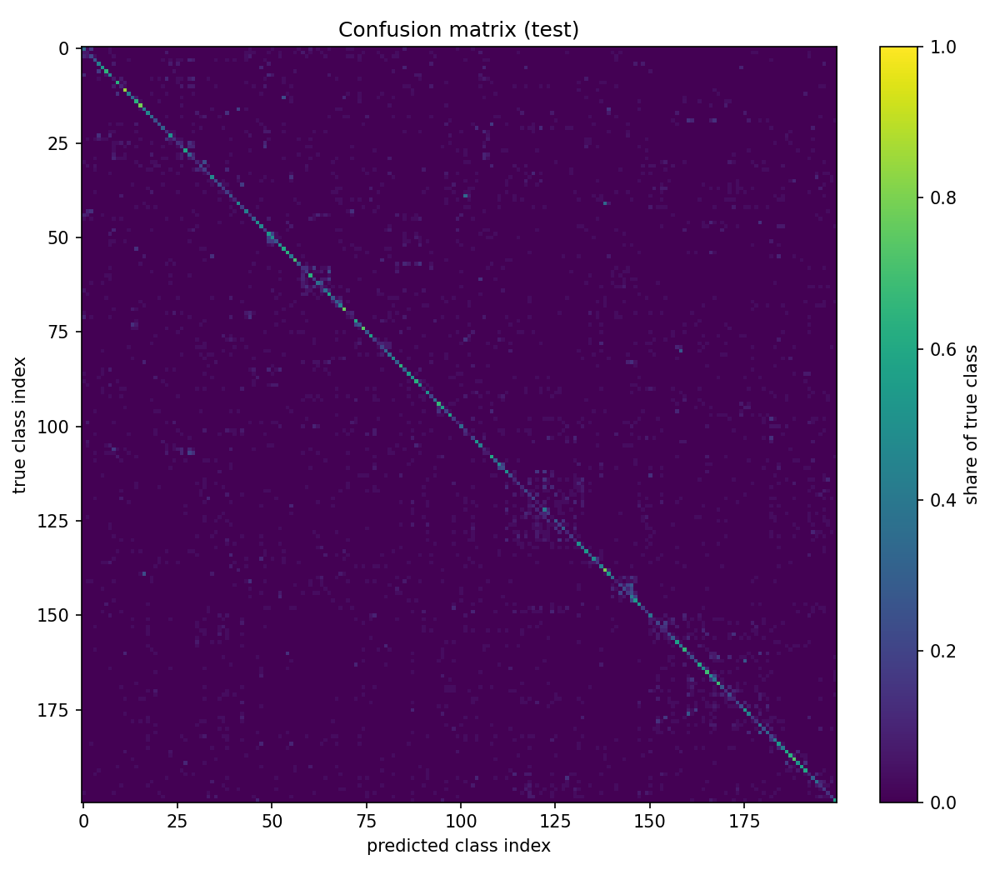

worst classes: [{'class': 'Sayornis', 'accuracy': 0.03333333333333333}, {'class': 'Lincoln Sparrow', 'accuracy': 0.034482758620689655}, {'class': 'Laysan Albatross', 'accuracy': 0.06666666666666667}, {'class': 'Mockingbird', 'accuracy': 0.06666666666666667}, {'class': 'Pomarine Jaeger', 'accuracy': 0.06666666666666667}]


In [7]:
from src.evaluation.evaluate import evaluate_checkpoint

CHECKPOINT = RUN_DIR / "best.pt"
eval_overrides = [o for o in overrides if o.startswith(("data.num_workers", "tracking."))]
split = "val" if QUICK_CHECK else "test"

report = evaluate_checkpoint(str(CHECKPOINT), split, eval_overrides)
display(ShowImage(filename=str(RUN_DIR / f"eval_{split}" / "confusion_matrix.png"), width=600))
print("worst classes:", report["worst_classes"][:5])

## 6. Grad-CAM — where the encoder looks (conv5)

Saved Grad-CAM figures to outputs/classification/alexnet_augmented/gradcam_test
correct


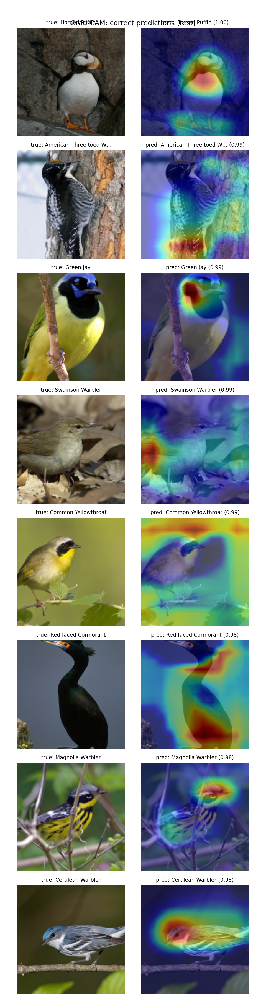

wrong


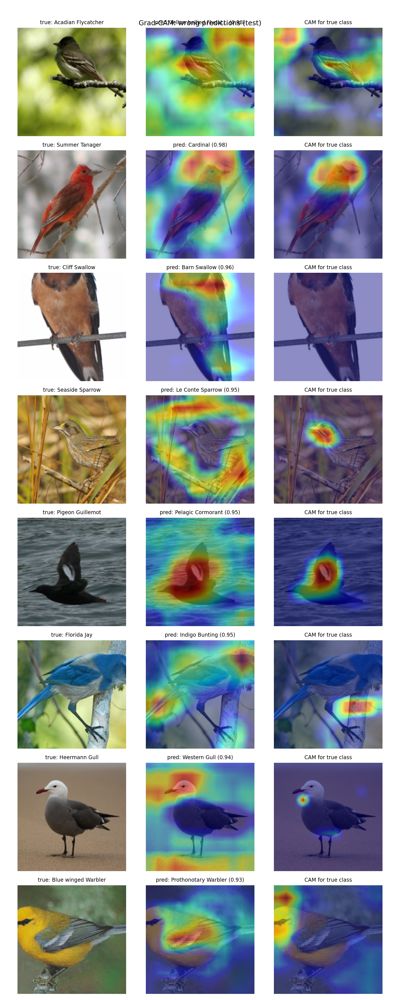

In [8]:
from src.visualization.gradcam import run_gradcam

figures = run_gradcam(str(CHECKPOINT), split, n_correct=8, n_wrong=8, overrides=eval_overrides)
for kind, path in figures.items():
    print(kind)
    display(ShowImage(filename=str(path)))

## 7. Comparison with the from-scratch ResNet (if its run is available)

In [9]:
from src.visualization.plots import plot_run_comparison

runs = {"AlexNet (+ augmented)": RUN_DIR,
        "ResNet (+ augmented)": Path(cfg["experiment"]["output_dir"]) / "scratch_B_augmented"}
histories = {}
for name, run_dir in runs.items():
    if (run_dir / "history.json").exists():
        with open(run_dir / "history.json", "r", encoding="utf-8") as f:
            histories[name] = json.load(f)
if len(histories) > 1:
    path = plot_run_comparison(histories, RUN_DIR / "comparison_resnet.png")
    display(ShowImage(filename=str(path)))
else:
    print("ResNet run not found; train it with the README commands to compare.")

ResNet run not found; train it with the README commands to compare.


## 8. Save the results

In [10]:
import shutil

if ON_KAGGLE:
    shutil.make_archive("/kaggle/working/alexnet_results", "zip", OUTPUTS)
elif ON_COLAB:
    archive = shutil.make_archive("/content/alexnet_results", "zip", OUTPUTS)
    print("results zipped to", archive)
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        target = "/content/drive/MyDrive/alexnet_outputs"
        shutil.copytree(OUTPUTS, target, dirs_exist_ok=True)
        print("results copied to Google Drive:", target)
    except Exception as error:
        print("Google Drive not available (", error, "): download", archive, "before the runtime closes")